# 08. Integrated validation and robustness

Original study laboratory. All generated data are synthetic.

Compare PI, fuzzy gain PID and feedforward PI at residence times 7,
10 and 14 min, using the same sensor-noise seed and reference/disturbance
schedule. Report IAE, ISE, ITAE, actuator energy, movement and violations.
Feedforward receives a disturbance measurement, so its information advantage
must be stated. These are synthetic matched scenarios, not measured evidence
or statistical confidence bounds. A final recommendation must state which
constraint or uncertainty determines the preferred controller.

## Prepare the environment

Run the next cell once in Colab. Locally, install `requirements.txt` and open this notebook within the repository. The cell only downloads the public repository when running in Colab and no checkout is present.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## Read the method visually

![Unit 08 conceptual diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/course/figures/learning/unit-08.png)

Rows change the process residence time, while columns change the controller. Within a row, target, disturbance and noise are matched. Evaluate error, effort, movement and constraint violations together. Feedforward receives an extra disturbance measurement; describe that advantage when interpreting the comparison.

The conceptual diagram is deliberately separate from the computed experiment below. [Editable SVG](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/figures/learning/unit-08.svg).

## Run the experiment

Read the model and controller definitions alongside the results. Every rerun writes the metrics, trace CSV files and figure from the current parameters. Unit 7 includes nested optimization and costs more than the other units.

In [2]:
from intelligent_control.experiments import run_unit
import json
result = run_unit(8, ROOT / "laboratories/08-integrated-validation/results")
print(json.dumps(result["summary"], indent=2))

{
  "scenarios": [
    {
      "method": "PI",
      "tau_min": 7.0,
      "iae": 2.7162001610510336,
      "ise": 0.29058294825387215,
      "itae": 99.46275282689194,
      "control_energy": 23.78138662077123,
      "total_variation": 3.9705555635584115,
      "constraint_violation": 0.0,
      "final_error": -0.008117820058093306
    },
    {
      "method": "fuzzy PID",
      "tau_min": 7.0,
      "iae": 3.3203395502642468,
      "ise": 0.3275615523682021,
      "itae": 123.88567045024051,
      "control_energy": 23.430263032174214,
      "total_variation": 3.8449794000094997,
      "constraint_violation": 0.0,
      "final_error": -0.014177821098773857
    },
    {
      "method": "feedforward PI",
      "tau_min": 7.0,
      "iae": 2.39937603992464,
      "ise": 0.2634700727376293,
      "itae": 80.83773700586849,
      "control_energy": 23.371874488071015,
      "total_variation": 4.026308931523395,
      "constraint_violation": 0.0,
      "final_error": -0.005701663988360528
  

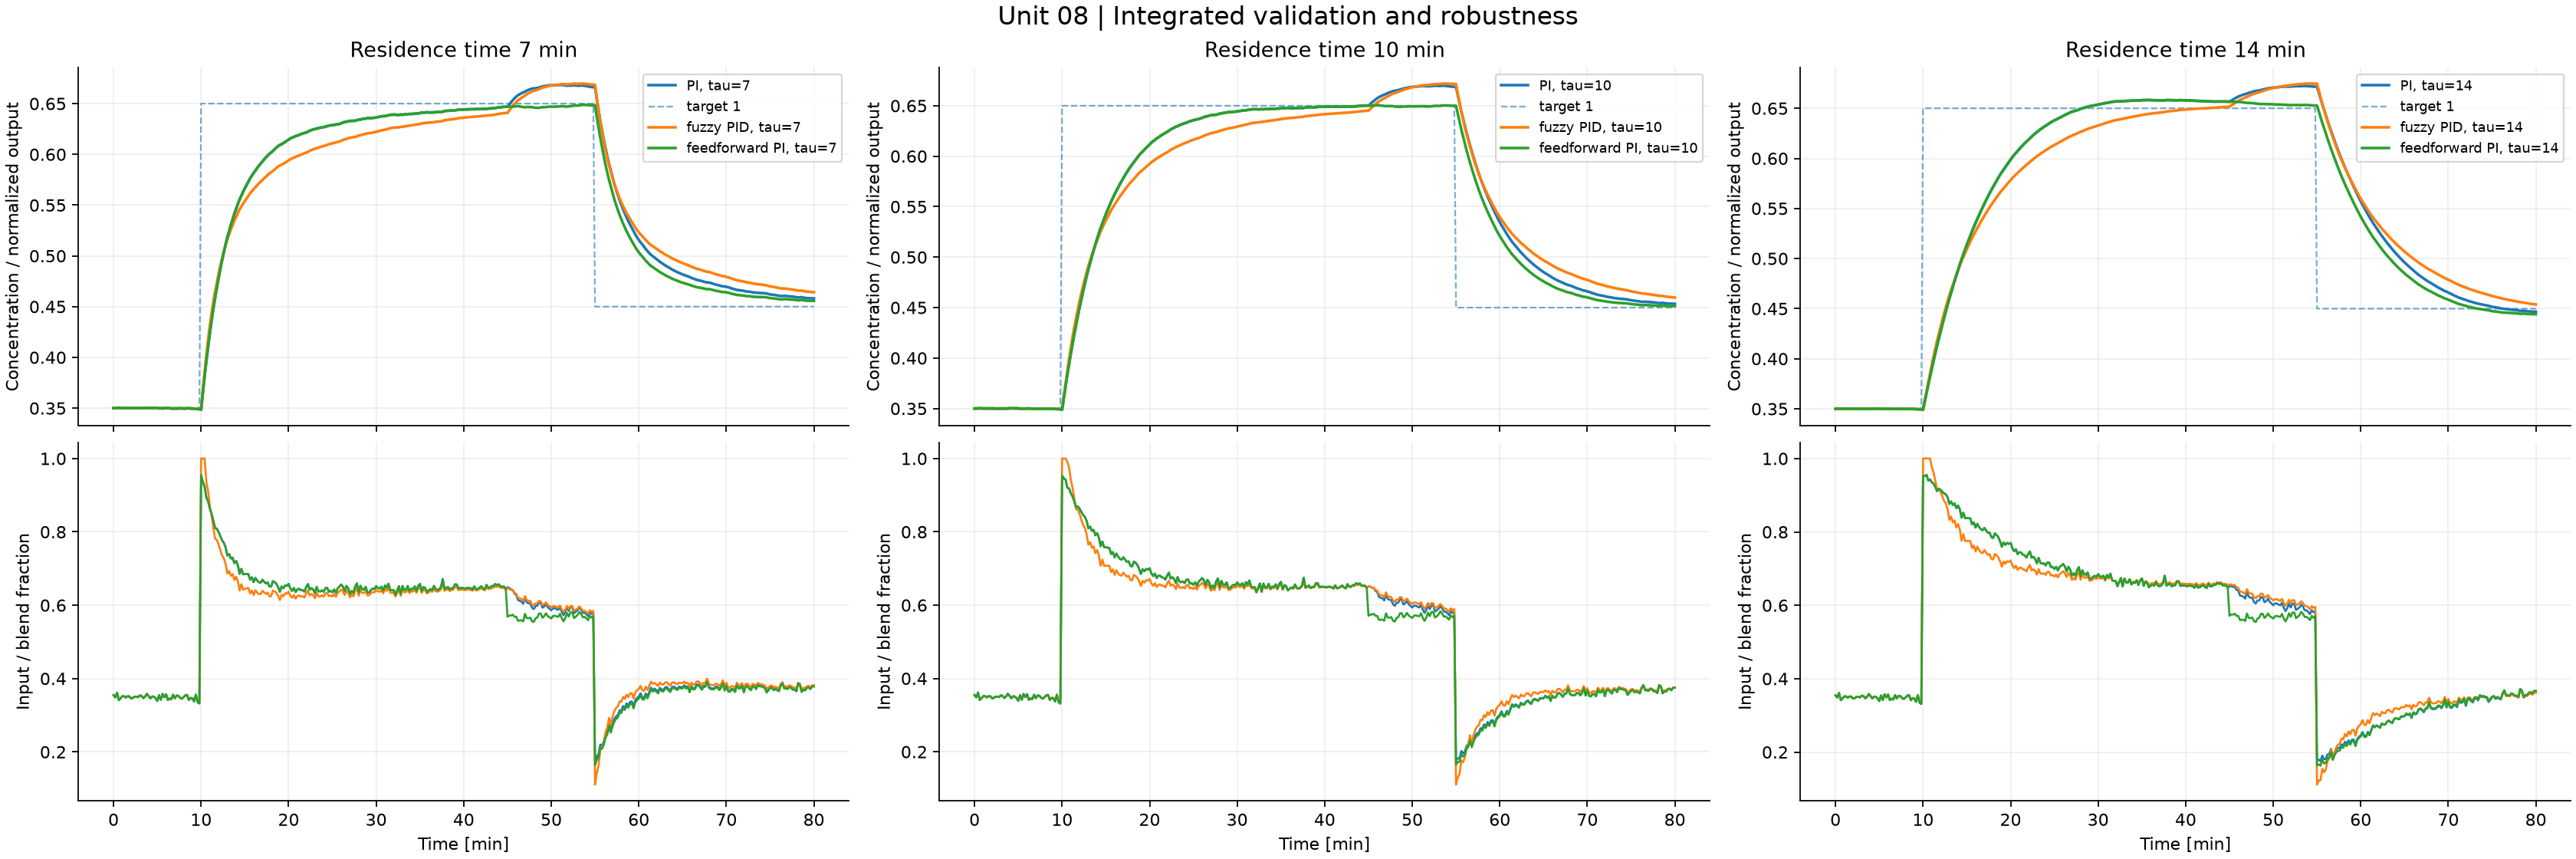

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "laboratories/08-integrated-validation/results/comparison.png")))

## Inspect the evidence

1. Identify the physical assumptions, input limits and units.
2. Explain a visible transient using the governing equation.
3. Change one model or controller parameter, rerun and compare the saved metrics.
4. State what the test does and does not establish.

Use the [course guide](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/README.md), [worked problems](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/problem-sets/README.md) and [benchmark inventory](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/README.md) for the corresponding derivations and extensions.

## Apply this unit to the article benchmarks

[Worked benchmark study for Unit 08](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/learning/unit-08.md)

![Unit 08 benchmark study](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/learning/figures/unit-08.png)

Read the per-model method, chosen signals, numerical results and interpretation in the linked study. The learning track declares its local-model approximations and separates equation-based experiments from external datasets and simulators. It does not turn an unavailable measured record into a synthetic benchmark result.